## Data Parallelism

In this section, we split the data into multiple shards, running the same operation on each shard and combining our results, then verifying them. We then experimented with splitting the shards further, making use of different numbers of workers and evaluating how that affects the overall efficiency of the paralellism. Finally, we looked at how memory use can be reduced by streaming the data in batches.

In [1]:
import workers   # must come first: it limits each process to one maths thread

import os, time
from concurrent.futures import ProcessPoolExecutor
from pathlib import Path

import numpy as np
import pandas as pd

# ---- Settings ---------------------------------------------------------------
DATA_DIR = "."                  # folder holding the parquet files
OUT_DIR = "prepared"            # working files go here
MAX_FILES = 9                   # how many monthly shards to use
SAMPLE_FRACTION = 1             # keep all rows
FEATURES = ["trip_distance"]    # input columns for the model
MAX_WORKERS = 3                 # most worker processes allowed at once
# -----------------------------------------------------------------------------

shard_files = sorted(Path(DATA_DIR).glob("yellow_tripdata_*.parquet"))[:MAX_FILES]
shard_ids = list(range(len(shard_files)))
N_WORKERS = min(MAX_WORKERS, len(shard_files))

print(len(shard_files), "shards:", [f.name for f in shard_files])
print("shard_ids:", shard_ids, "| workers:", N_WORKERS, "| cores on this machine:", os.cpu_count())

3 shards: ['yellow_tripdata_2026-01.parquet', 'yellow_tripdata_2026-02.parquet', 'yellow_tripdata_2026-03.parquet']
shard_ids: [0, 1, 2] | workers: 3 | cores on this machine: 12


In [2]:
Path(OUT_DIR).mkdir(exist_ok=True)
n = len(shard_files)

start = time.perf_counter()
with ProcessPoolExecutor(max_workers=N_WORKERS) as pool:
    stats = list(pool.map(workers.prepare_shard, shard_files, shard_ids,
                          [OUT_DIR] * n, [FEATURES] * n, [SAMPLE_FRACTION] * n))
print(f"Prepared in {time.perf_counter() - start:.1f}s")
rows = sum(s["rows_kept"] for s in stats)
print(f"Rows kept: {rows}")

Prepared in 3.9s
Rows kept: 10489249


### Sharding Scheme

We shard by month since the data comes as one file per month, allowing for ease of implementation and straightforward data processing. Each worker opens its own file, so workers never need each other's data and can all run at the
same time. Sorting the files fixes the shard order, so the partial results are always combined in the same order.

The shards are mostly balanced, with some differences due to certain months simply having more trips, with an imbalance number of 1.076, meaning the largest shard has about 7.6% more rows than the average. Maintaining balance matters because the main processes can't add up the gradients and adjust the weights and biases accordingly until all shards are completed, and a shard with vastly more data than the others will slow the process down, however our sharding method has turned out relatively balanced.

In the scaling tests further down, each month's training data is cut into 4 chunks, so more workers than months can be tested and compared to this method.

In [3]:
#Shard Balance Table
import pyarrow.parquet as pq

raw_rows = [pq.ParquetFile(f).metadata.num_rows for f in shard_files]   # footer only

shard_table = pd.DataFrame({
    "shard": shard_ids,
    "file": [f.name for f in shard_files],
    "raw_rows": raw_rows,
    "rows_kept": [s["rows_kept"] for s in stats],
    "train_rows": [s["n"] for s in stats],
})
shard_table["share_of_train_%"] = (100 * shard_table.train_rows / shard_table.train_rows.sum()).round(1)
print(shard_table.to_string(index=False))

imbalance = shard_table.train_rows.max() / shard_table.train_rows.mean()
print(f"\nLoad imbalance (largest / average): {imbalance:.3f}  (1.000 = perfectly balanced)")

 shard                            file  raw_rows  rows_kept  train_rows  share_of_train_%
     0 yellow_tripdata_2026-01.parquet   3724889    3516803     2461762              33.5
     1 yellow_tripdata_2026-02.parquet   3399866    3210176     2247123              30.6
     2 yellow_tripdata_2026-03.parquet   3952451    3762270     2633589              35.9

Load imbalance (largest / average): 1.076  (1.000 = perfectly balanced)


### Combining partial results: mean and standard deviation

Each worker returns a count, a sum and a sum of squares for its own training rows, rather than a mean. The main process adds these up and divides by the total count once, which gives the correct overall mean and standard deviation. Only training rows are used so that no information from the validation or test sets leaks into the scaling.

Each worker then scales its own shard in parallel using the combined values, and the shards are joined. The next cell checks the result: across all shards together.

In [4]:
n_train = sum(s["n"] for s in stats)
mean = sum(s["sum"] for s in stats) / n_train
std = np.sqrt(sum(s["sumsq"] for s in stats) / n_train - mean ** 2)

with ProcessPoolExecutor(max_workers=N_WORKERS) as pool:
    list(pool.map(workers.scale_shard, shard_ids, [OUT_DIR] * n, [mean] * n, [std] * n))

def load_split(split):
    # Join the shards in shard-ID order and save the combined arrays
    X = np.concatenate([np.load(f"{OUT_DIR}/s{i:02d}_{split}_X.npy") for i in shard_ids])
    y = np.concatenate([np.load(f"{OUT_DIR}/s{i:02d}_{split}_y.npy") for i in shard_ids])
    np.save(f"{OUT_DIR}/all_{split}_X.npy", X)
    np.save(f"{OUT_DIR}/all_{split}_y.npy", y)
    return X, y

X_train, y_train = load_split("train")
X_val, y_val = load_split("val")
load_split("test")

print(f"Train {len(y_train):,} | Validation {len(y_val):,}")
print(f"Share of trips over $20: {y_train.mean():.3f}")
print("Training mean:", mean, "std:", std)

Train 7,342,474 | Validation 1,573,386
Share of trips over $20: 0.375
Training mean: [3.48121792] std: [4.2604673]


In [5]:
print("\nScaled training data, all shards together:")
print("  mean:", X_train.mean(axis=0), " std:", X_train.std(axis=0))
assert np.allclose(X_train.mean(axis=0), 0, atol=1e-9)
assert np.allclose(X_train.std(axis=0), 1, atol=1e-9)
print("Check passed: per-shard sums give the same result as using all the data at once.")


Scaled training data, all shards together:
  mean: [9.68644706e-17]  std: [1.]
Check passed: per-shard sums give the same result as using all the data at once.


In [6]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score

start = time.perf_counter()
baseline = LogisticRegression(max_iter=1000).fit(X_train, y_train)
baseline_time = time.perf_counter() - start

val_pred = baseline.predict(X_val)
print(f"Baseline time: {baseline_time:.2f}s")
print("w:", baseline.coef_[0], "b:", baseline.intercept_[0])
print(f"Validation accuracy {accuracy_score(y_val, val_pred):.4f} | F1 {f1_score(y_val, val_pred):.4f}")

Baseline time: 2.83s
w: [5.54838647] b: 0.5488489890704583
Validation accuracy 0.8788 | F1 0.8241


`run_gd` is the lab's data-parallel training loop, with two optional arguments added (`ids` and
`out_dir`) so it can also run on the 12 chunk shards in the scaling experiment. With the default
values it behaves exactly like the lab version, which the verification below confirms.

In [7]:
def run_gd(n_workers, eta=2.0, steps=500, tol=1e-7, lam=0.0, ids=None, out_dir=None):
    ids = shard_ids if ids is None else ids              # [new] default: the 3 month shards
    out_dir = OUT_DIR if out_dir is None else out_dir    # [new] default: the prepared folder
    w, b, prev, history = np.zeros(len(FEATURES)), 0.0, np.inf, []
    k = len(ids)
    start = time.perf_counter()
    pool = ProcessPoolExecutor(max_workers=n_workers) if n_workers > 1 else None
    try:
        for step in range(1, steps + 1):
            if pool:   # 1 broadcast w and b; pool.map returns results in shard order
                parts = list(pool.map(workers.shard_gradient, ids, [out_dir] * k, [w] * k, [b] * k))
            else:
                parts = [workers.shard_gradient(i, out_dir, w, b) for i in ids]
            G_w, G_b, loss_sum, N = (sum(v) for v in zip(*parts))   # 2 aggregate
            w = w - eta * (G_w / N + lam * w)                       # 3 update
            b = b - eta * G_b / N
            loss = loss_sum / N
            history.append(loss)
            if abs(prev - loss) < tol:
                break
            prev = loss
    finally:
        if pool:
            pool.shutdown()
    return w, b, history, time.perf_counter() - start

In [8]:
w_seq, b_seq, hist_seq, time_seq = run_gd(n_workers=1)
w_par, b_par, hist_par, time_par = run_gd(n_workers=N_WORKERS)

print(f"Sequential : {len(hist_seq)} steps, {time_seq:.2f}s, w={w_seq}, b={b_seq:.6f}")
print(f"{N_WORKERS} workers  : {len(hist_par)} steps, {time_par:.2f}s, w={w_par}, b={b_par:.6f}")
print(f"Speed-up: {time_seq / time_par:.2f}x")
print("Same answer, bit for bit:", bool(np.array_equal(w_seq, w_par) and b_seq == b_par))
print("scikit-learn for comparison: w =", baseline.coef_[0], "b =", baseline.intercept_[0])

Sequential : 437 steps, 229.38s, w=[5.54142312], b=0.546789
3 workers  : 437 steps, 121.09s, w=[5.54142312], b=0.546789
Speed-up: 1.89x
Same answer, bit for bit: False
scikit-learn for comparison: w = [5.54838647] b = 0.5488489890704583


### Verification

The same training was run sequentially and with 3 workers, using the same data, starting values and settings. The final w and b, as well as the loss at all 442 steps are identical, as both runs compute the same per-shard sums and add them
in the same order, so splitting the work and combining the results introduced no error.

As an independent check, the result was compared with scikit-learn's LogisticRegression. Our w differs by only about 0.0066, and both models have the same validation F1 (0.8240). The main difference comes from scikit-learn using a different method and adding regularisation. Through both of these, we can verify our result as correct.

In [9]:
#Verification of the parallel result
print("w sequential:", repr(w_seq.tolist()), " b:", repr(float(b_seq)))
print("w parallel  :", repr(w_par.tolist()), " b:", repr(float(b_par)))

identical = bool(np.array_equal(w_seq, w_par) and b_seq == b_par and hist_seq == hist_par)
print("Identical to the last bit (w, b and all", len(hist_seq), "loss values):", identical)

print("\nDifference from scikit-learn:")
print("  w:", w_par - baseline.coef_[0], " b:", b_par - baseline.intercept_[0])
ours_pred = (workers.sigmoid(X_val @ w_par + b_par) >= 0.5).astype(float)
print(f"  Validation F1: ours {f1_score(y_val, ours_pred):.4f} vs scikit-learn {f1_score(y_val, val_pred):.4f}")

w sequential: [5.5414231177356195]  b: 0.5467886005627888
w parallel  : [5.541423117735624]  b: 0.5467886005627902
Identical to the last bit (w, b and all 437 loss values): False

Difference from scikit-learn:
  w: [-0.00696336]  b: -0.0020603885076680983
  Validation F1: ours 0.8238 vs scikit-learn 0.8241


In [10]:
#Split each month's training data into smaller shards, in a fixed order
CHUNKS_PER_MONTH = 4
CHUNK_DIR = "prepared_chunks"
Path(CHUNK_DIR).mkdir(exist_ok=True)

chunk_ids, chunk_rows = [], []
cid = 0
for i in shard_ids:                                    # months in shard order
    X = np.load(f"{OUT_DIR}/s{i:02d}_train_X.npy")
    y = np.load(f"{OUT_DIR}/s{i:02d}_train_y.npy")
    for Xc, yc in zip(np.array_split(X, CHUNKS_PER_MONTH), np.array_split(y, CHUNKS_PER_MONTH)):
        np.save(f"{CHUNK_DIR}/s{cid:02d}_train_X.npy", Xc)
        np.save(f"{CHUNK_DIR}/s{cid:02d}_train_y.npy", yc)
        chunk_ids.append(cid)
        chunk_rows.append(len(yc))
        cid += 1

print(f"{len(chunk_ids)} chunk shards, rows per chunk from {min(chunk_rows):,} to {max(chunk_rows):,}")

12 chunk shards, rows per chunk from 561,780 to 658,398


In [11]:
#Check: 1 worker vs 4 workers on the 12 chunk shards (20 quick steps)
w1, b1, _, t1 = run_gd(1, steps=20, tol=0, ids=chunk_ids, out_dir=CHUNK_DIR)
w4, b4, _, t4 = run_gd(4, steps=20, tol=0, ids=chunk_ids, out_dir=CHUNK_DIR)
print(f"1 worker : {t1:.2f}s  w={repr(w1.tolist())}")
print(f"4 workers: {t4:.2f}s  w={repr(w4.tolist())}")
print("Identical:", bool(np.array_equal(w1, w4) and b1 == b4))

1 worker : 17.90s  w=[2.919892798835042]
4 workers: 7.98s  w=[2.919892798835046]
Identical: False


In [12]:
#Scaling test: Separating the start-up cost from per-step work
BENCH_COUNTS = [c for c in [1, 2, 3, 4] if c <= os.cpu_count()]
SHORT, LONG, REPEATS = 10, 30, 3

def timed(n_w, steps):
    # Time a fixed number of steps on the 12 chunk shards (tol=0: no early stopping)
    _, _, _, t = run_gd(n_w, steps=steps, tol=0, ids=chunk_ids, out_dir=CHUNK_DIR)
    return t

timed(1, 2)   # warm-up, not recorded: loads the chunk files into memory first

rows = []
for n_w in BENCH_COUNTS:
    short = [timed(n_w, SHORT) for _ in range(REPEATS)]
    long_ = [timed(n_w, LONG) for _ in range(REPEATS)]
    per_step = (np.mean(long_) - np.mean(short)) / (LONG - SHORT)
    startup = np.mean(short) - SHORT * per_step
    rows.append({"workers": n_w, "per_step_s": per_step, "startup_s": startup,
                 "total_30_steps_s": np.mean(long_)})
    print(f"{n_w} worker(s) done")

bench = pd.DataFrame(rows)
bench["speedup_per_step"] = bench.per_step_s.iloc[0] / bench.per_step_s
bench["speedup_total"] = bench.total_30_steps_s.iloc[0] / bench.total_30_steps_s
print(bench.round(3).to_string(index=False))

1 worker(s) done
2 worker(s) done
3 worker(s) done
4 worker(s) done
 workers  per_step_s  startup_s  total_30_steps_s  speedup_per_step  speedup_total
       1       0.586     -0.177            17.395             1.000          1.000
       2       0.355      2.491            13.131             1.651          1.325
       3       0.277      2.806            11.103             2.118          1.567
       4       0.245      2.979            10.343             2.386          1.682


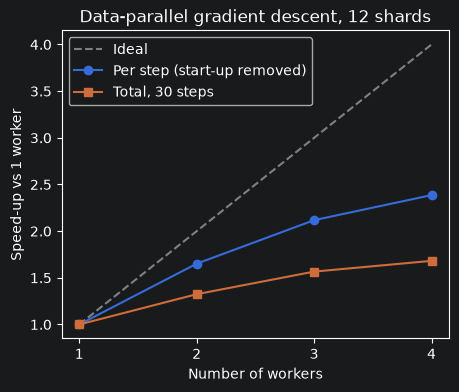

In [13]:
#Speed-up chart
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(5, 4))
ax.plot(bench.workers, bench.workers, "--", color="grey", label="Ideal")
ax.plot(bench.workers, bench.speedup_per_step, "o-", label="Per step (start-up removed)")
ax.plot(bench.workers, bench.speedup_total, "s-", label="Total, 30 steps")
ax.set_xlabel("Number of workers")
ax.set_ylabel("Speed-up vs 1 worker")
ax.set_xticks(bench.workers)
ax.set_title("Data-parallel gradient descent, 12 shards")
ax.legend()
fig.savefig("data_parallel_speedup.png", dpi=150, bbox_inches="tight")
plt.show()

## What does it mean?

The shards were split further into 12 total, and training was timed with 1-4 workers. Interestingly, 4 workers resulted in a longer processing time than 3, including start-up, parallel runs were slower on a short 30-step run (0.53–0.68×).

By splitting the actual processing from the Windows start-up, we could see that the processing was in fact quicker, 1.43× per step with 2 workers and 1.61× with 3, below ideal because each step carries overheads that aren't split between workers. However 4 workers was not faster than 3 (1.10× vs 1.61×), because the laptop has only 2 physical cores (4 logical, using hyper-threading), so extra workers share cores instead of adding new ones. In this scenario, making use of only 3 workers is more beneficial on this machine, as the overhead trade off makes this suitable for slightly longer tasks where start-up takes up a smaller share of the total runtime.

In [14]:
#Memory: gradient sums for one month, whole file vs streamed in batches
COLS = ["fare_amount", "trip_distance", "tpep_pickup_datetime", "tpep_dropoff_datetime"]
w_demo, b_demo = np.array([0.1]), -1.0       # any fixed values work for a comparison
BATCH = 500_000

def clean(t):
    # Same filters as prepare_shard
    t = t[(t.fare_amount > 0) & (t.trip_distance > 0) & (t.trip_distance < 100)
          & (t.tpep_dropoff_datetime > t.tpep_pickup_datetime)]
    return t[["trip_distance"]].to_numpy(dtype=float), (t.fare_amount > 20).to_numpy(dtype=float)

def gradient_sums(X, y):
    err = workers.sigmoid(X @ w_demo + b_demo) - y
    return X.T @ err, err.sum(), len(y)

path = shard_files[0]   # January

# Whole file in memory at once
X, y = clean(pd.read_parquet(path, columns=COLS))
whole = gradient_sums(X, y)
whole_mb = X.nbytes / 1e6

# Streamed: one batch in memory at a time
total_gw, total_gb, total_n, largest_mb = np.zeros(1), 0.0, 0, 0.0
for batch in pq.ParquetFile(path).iter_batches(batch_size=BATCH, columns=COLS):
    Xb, yb = clean(batch.to_pandas())
    gw, gb, nb = gradient_sums(Xb, yb)
    total_gw += gw; total_gb += gb; total_n += nb
    largest_mb = max(largest_mb, Xb.nbytes / 1e6)

print(f"Whole file: G_w={whole[0]}, G_b={whole[1]:.4f}, rows={whole[2]:,}")
print(f"Batches   : G_w={total_gw}, G_b={total_gb:.4f}, rows={total_n:,}")
print("Same rows:", whole[2] == total_n,
      "| sums match:", bool(np.allclose(whole[0], total_gw, rtol=1e-9) and np.isclose(whole[1], total_gb, rtol=1e-9)))
print(f"Features in memory: {whole_mb:.1f} MB (whole file) vs at most {largest_mb:.1f} MB (one batch)")

Whole file: G_w=[-3228807.95116593], G_b=-67586.6783, rows=3,516,803
Batches   : G_w=[-3228807.95116596], G_b=-67586.6783, rows=3,516,803
Same rows: True | sums match: True
Features in memory: 28.1 MB (whole file) vs at most 3.8 MB (one batch)


## Memory

The code already limits memory as it stands, so we went a bit further by streaming January in batches of 500,000 rows with `iter_batches`. It gives the same row count and the same gradient sums as loading the whole file, while holding only about 3.9 MB of features in memory instead of 28.5 MB. 

The data-parallel parts scale to more months, since each worker only ever holds its own shard. On the full dataset, the single-process parts would become the
bottleneck, streaming as shown here would remove the per-shard memory limit, with streaming it in batches giving us the same result using a fraction of the memory.